# 8. Atmosphere knobs

What each parametric-model knob does to a spectrum, on two very different
planets: the hot Jupiter **WASP-39 b** and the temperate sub-Neptune
**K2-18 b**. For every sweep we track the feature amplitude (max − min of
the binned spectrum over 0.40–1.70 µm) and the template S/N for one transit,
then ask how many transits reach S/N = 5.

The model is isothermal equilibrium chemistry with a gray deck and a
power-law haze; the knobs are the ones the Lazuli simulators page exposes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
try:
    plt.style.use("gks")
except OSError:
    pass

import lazuli_exo
from lazuli_exo import presets

BASE = {name: presets.showcase(name, "clear") for name in ("WASP-39 b", "K2-18 b")}


def run(name, **edit):
    o = lazuli_exo.simulate({**BASE[name], **edit}, R=100, n_transits=1)
    return o, o.meta["atmosphere"]["feature_amplitude_ppm"], o.detect()["template_snr_diagonal"]


def sweep(knob, values, **fixed):
    out = {}
    for name in BASE:
        rows = []
        for v in values:
            _, amp, snr = run(name, **{knob: v}, **fixed)
            rows.append((v, amp, snr, (5.0 / snr) ** 2 if snr > 0 else np.inf))
        out[name] = np.array(rows)
    return out


def show(res, knob, xlabel, logx=False):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    for name, rows in res.items():
        for k, (ylabel, j) in enumerate((("feature amplitude [ppm]", 1), ("template S/N, 1 transit", 2), ("transits to S/N = 5", 3))):
            ax[k].plot(rows[:, 0], rows[:, j], "o-", ms=4, label=name)
            ax[k].set_ylabel(ylabel)
    for a in ax:
        a.set_xlabel(xlabel); a.set_yscale("log")
        if logx:
            a.set_xscale("log")
    ax[2].axhline(1, color="0.7", lw=0.8); ax[2].axhline(100, color="0.7", lw=0.8)
    ax[0].legend(frameon=False, fontsize=8)
    fig.suptitle(knob); fig.tight_layout()

## Mean molecular weight

H ∝ 1/μ, so the amplitude falls as 1/μ and the transits needed rise as μ². `mu=None` would take the equilibrium-chemistry value (2.3 at solar metallicity).

{'WASP-39 b': [0, 0, 0, 0, 1], 'K2-18 b': [1, 3, 13, 52, 171]}


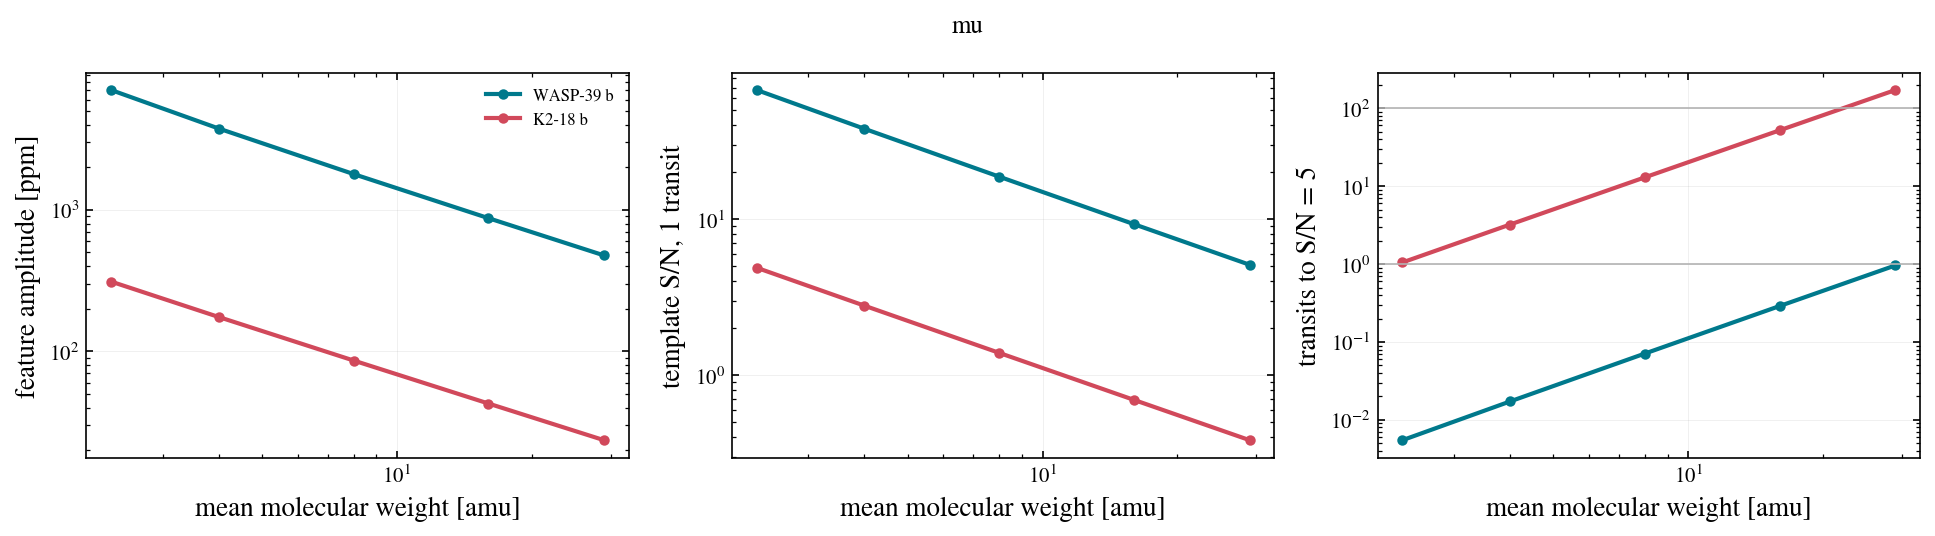

In [2]:
res = sweep("mu", [2.3, 4, 8, 16, 29])
show(res, "mu", "mean molecular weight [amu]", logx=True)
print({name: np.round(rows[:, 3]).astype(int).tolist() for name, rows in res.items()})

## Metallicity

The grid runs from 0.1× to 1000× solar. Above ~100× the chemistry-derived μ climbs steeply, which is what flattens the spectrum; up to there the opacity changes more than the amplitude does.

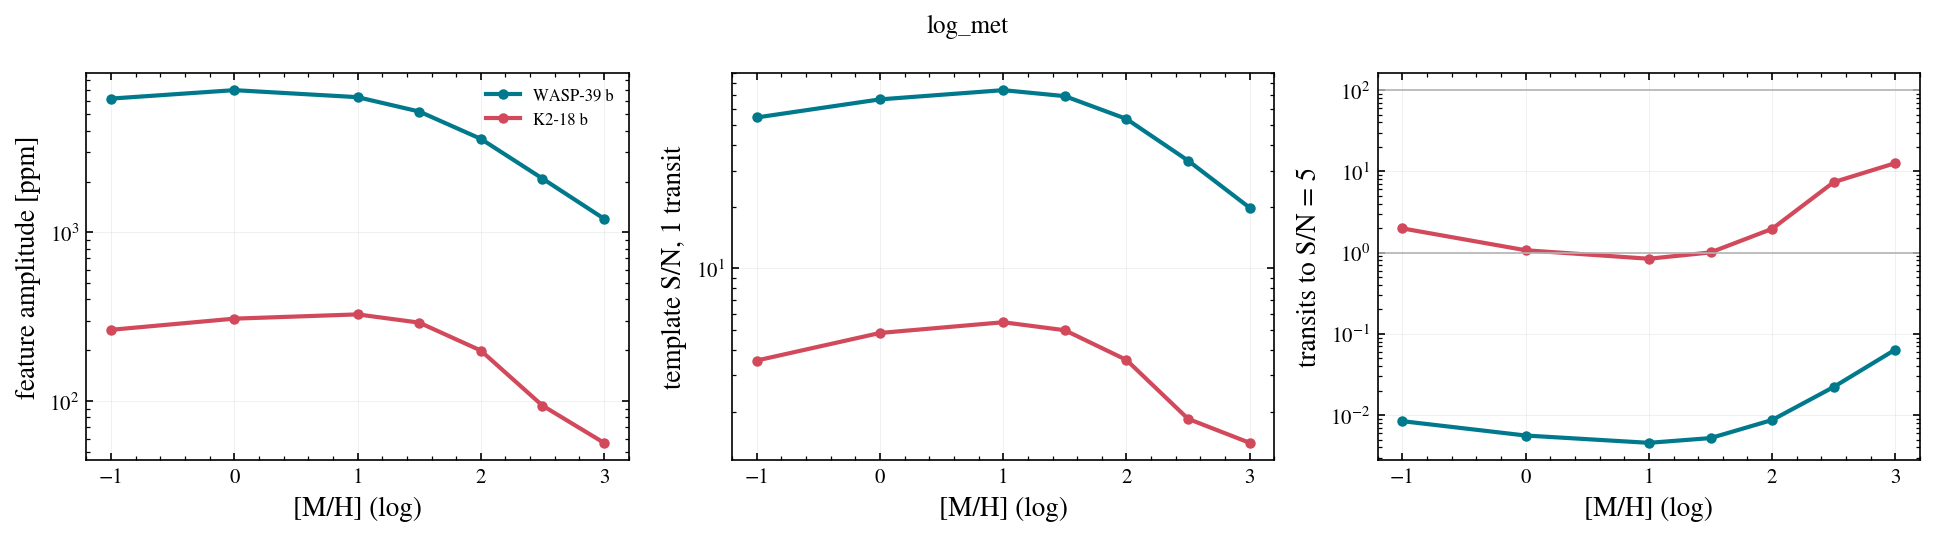

In [3]:
res = sweep("log_met", [-1, 0, 1, 1.5, 2, 2.5, 3])
show(res, "log_met", "[M/H] (log)")

## Cloud deck pressure

A gray deck hides everything below it. Features survive only where the clear photosphere sits above the deck; the operator keeps the partially transparent gas just below the deck top (see the user guide), so the transition is smooth rather than a hard cut.

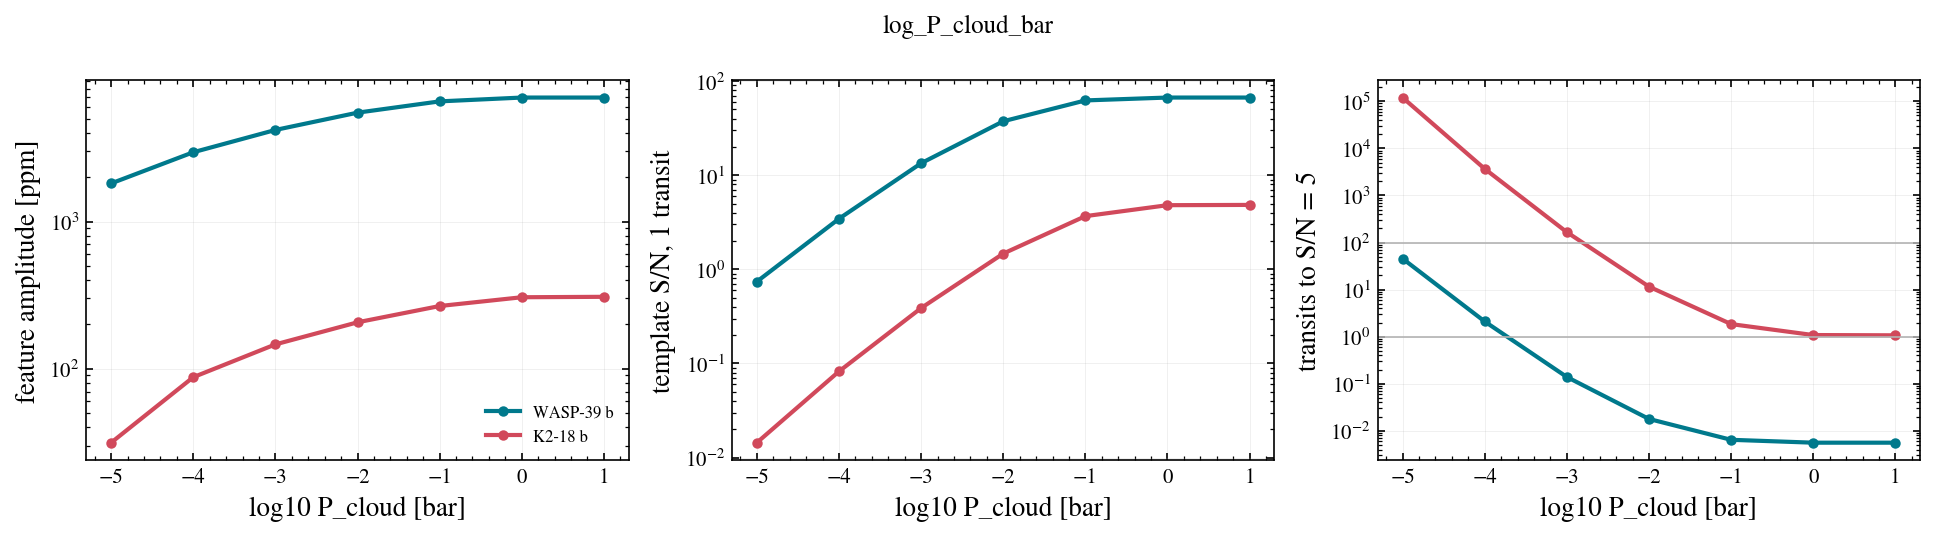

In [4]:
res = sweep("log_P_cloud_bar", [1, 0, -1, -2, -3, -4, -5])
show(res, "log_P_cloud_bar", "log10 P_cloud [bar]")

## Haze

POSEIDON's MacMad17 form: κ_haze = n · 10^log_a · σ_H2(0.35 µm) · (λ/0.35 µm)^γ. The slope γ = −4 is Rayleigh-like; −2 is flatter and mutes the red end less. Note that haze can *raise* the template S/N by adding a steep blue slope.

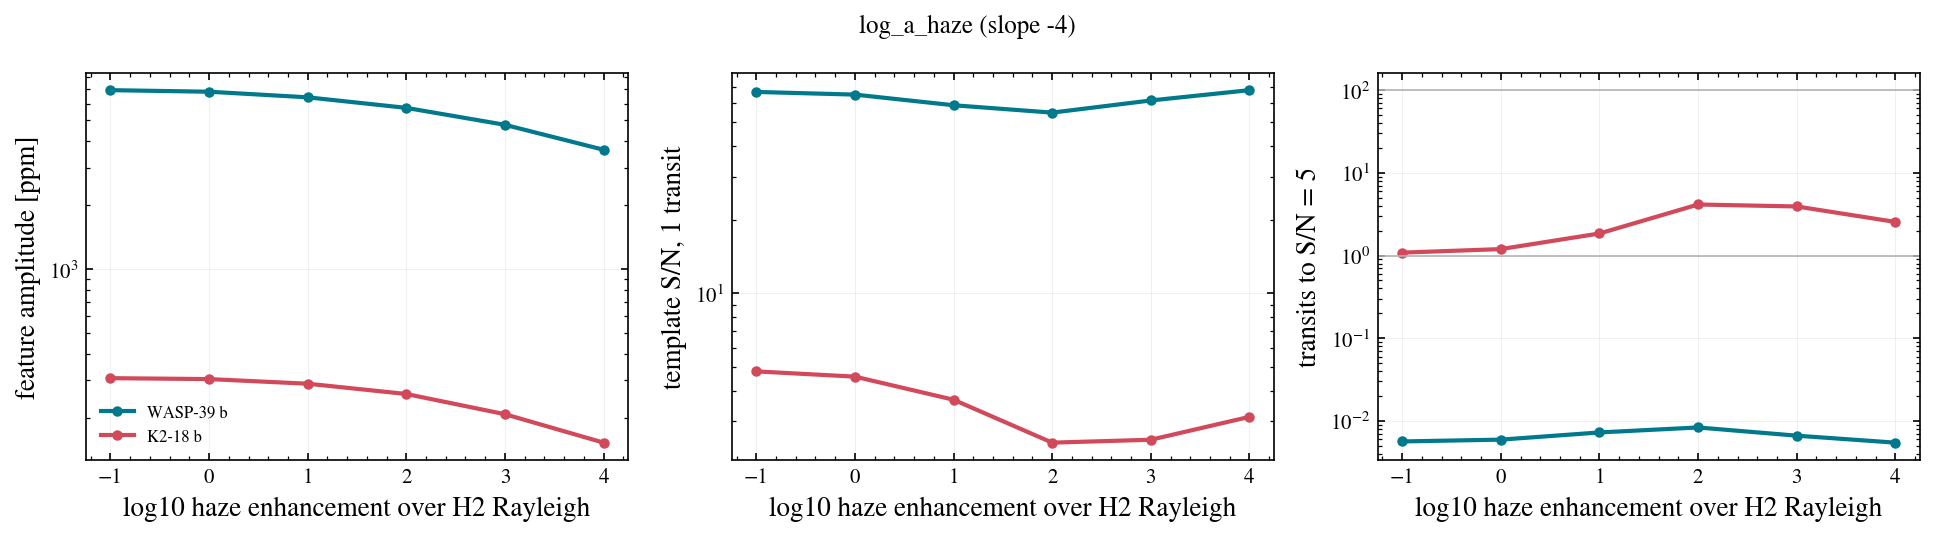

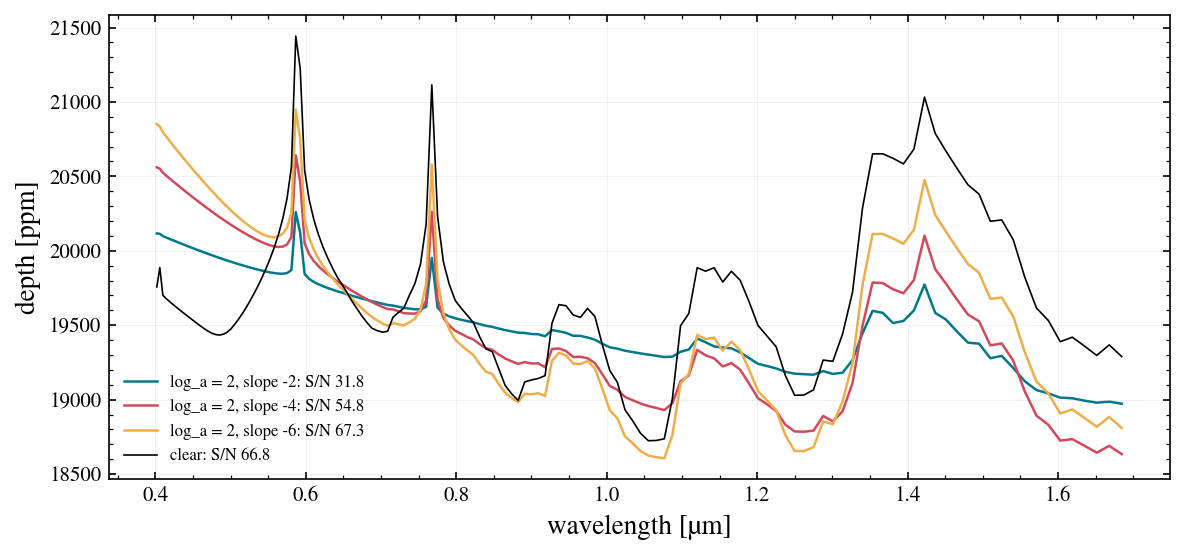

In [5]:
res = sweep("log_a_haze", [-1, 0, 1, 2, 3, 4], haze_slope=-4.0)
show(res, "log_a_haze (slope -4)", "log10 haze enhancement over H2 Rayleigh")
fig, ax = plt.subplots(figsize=(8, 3.8))
for gamma in (-2.0, -4.0, -6.0):
    o, amp, snr = run("WASP-39 b", log_a_haze=2.0, haze_slope=gamma)
    ax.plot(o.wavelength, o.depth * 1e6, lw=1.2, label=f"log_a = 2, slope {gamma:+.0f}: S/N {snr:.1f}")
o, amp, snr = run("WASP-39 b"); ax.plot(o.wavelength, o.depth * 1e6, "k", lw=0.8, label=f"clear: S/N {snr:.1f}")
ax.set_xlabel("wavelength [µm]"); ax.set_ylabel("depth [ppm]"); ax.legend(frameon=False, fontsize=8); fig.tight_layout()

## Temperature

T_eq sets H directly and the chemistry indirectly (the chemistry lookup is clamped at the 300 K grid floor; H always uses the true T_eq, and `info['T_clamped']` says when the clamp applied).

K2-18 b at its own T_eq: {'T_chem_K': 300.0, 'T_clamped': True, 'H_m': 64869.57592934556}


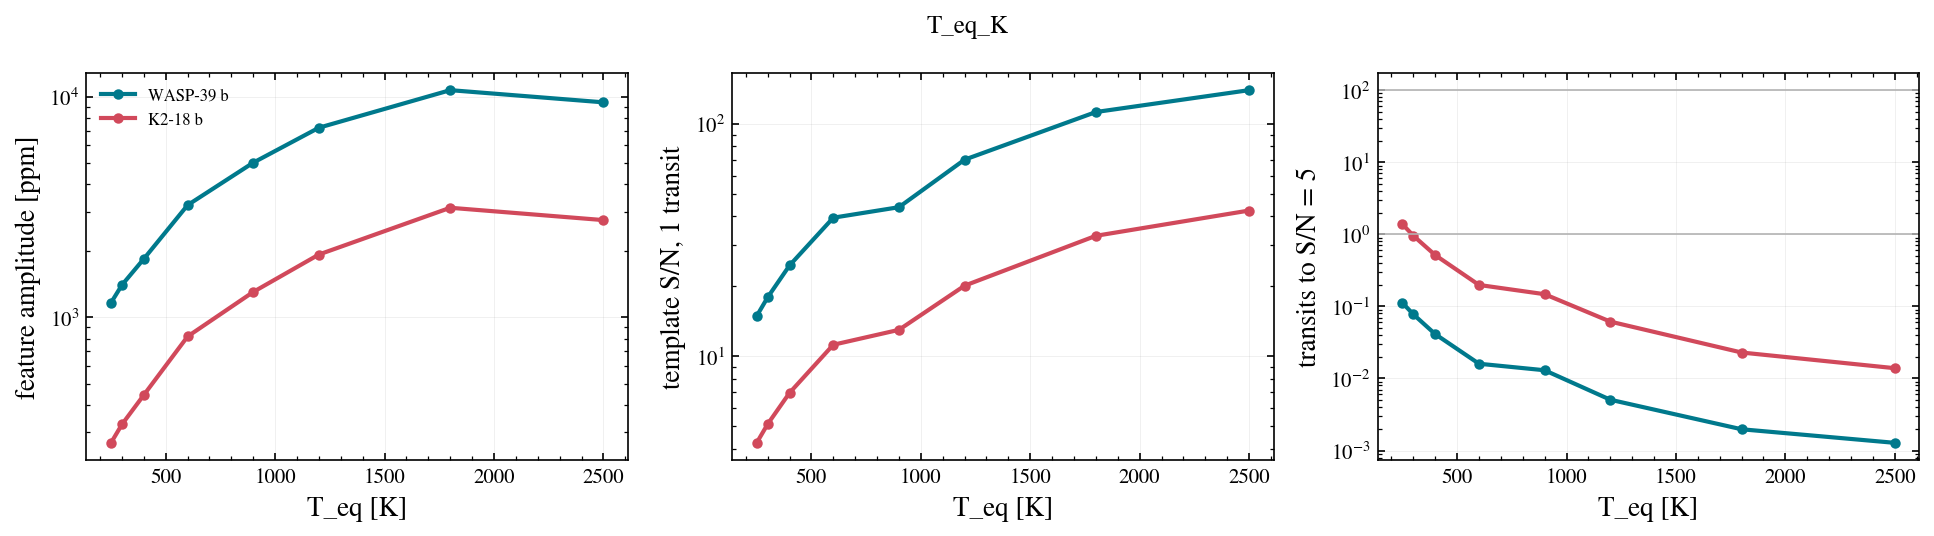

In [6]:
res = sweep("T_eq_K", [250, 300, 400, 600, 900, 1200, 1800, 2500])
show(res, "T_eq_K", "T_eq [K]")
_, info = lazuli_exo.atmosphere.transmission_depth(lazuli_exo.atmosphere.grid_wavelengths(), **{k: BASE["K2-18 b"][k] for k in ("T_eq_K", "R_p_RJ", "M_p_MJ", "R_s_RSun")})
print("K2-18 b at its own T_eq:", {k: info[k] for k in ("T_chem_K", "T_clamped", "H_m")})

## Summary

- μ and the cloud deck are the two knobs that can erase a spectrum; metallicity acts mostly through μ above ~100× solar.
- Haze trades red-end amplitude for a blue slope and can increase the template S/N.
- Transits needed scale as (5 / S/N₁)², so a factor 2 in amplitude is a factor 4 in time.